# 03 · Compare HTEM algorithms on identical prepared data

Run `02` and `examples/02a`, `02b`, `02c`, `02d` first. This short notebook **does not train or alter data**.
It checks preparation/preprocessing hashes, exact labeled-point identities/targets, result checksums,
and the held-out map example before assembling results. Missing/stale runs produce a clear error.
Rank by **validation**, not test. The default workshop 02 remains linear Ridge regardless of rank.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Verify and assemble saved architecture results

Code Summary: Loads verified results from five models trained on the shared features, without retraining. Compares expanded test observations and the original paired holdout separately, with model ranking based on validation performance.


In [1]:
from pathlib import Path
import sys, json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
HERE = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / '03_htem_conductivity']:
        if (candidate / 'lib/htem_experiments.py').exists():
            HERE = candidate
            break
    if HERE is not None: break
if HERE is None:
    raise FileNotFoundError('Open from the workshop, HTEM module, or its examples folder.')
sys.path.insert(0, str(HERE / 'lib'))
import htem_workshop as htem
import htem_experiments as exp
ctx = exp.load_context(HERE)  # Validate and reuse notebook 01; NEVER redo preparation/splitting.
print('Shared frozen feature set:', ctx.manifest['frozen_feature_selection']['candidate'])
SEED = ctx.manifest['seed']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

comparison = exp.collect_comparison(ctx)
COMPARISON = HERE / 'outputs/htem_architectures/comparison'
COMPARISON.mkdir(parents=True, exist_ok=True)
comparison.to_csv(COMPARISON / 'architecture_summary.csv', index=False)
display(comparison[['algorithm', 'validation_score', 'train_scaled_MSE', 'validation_scaled_MSE',
                    'test_scaled_MSE', 'test_thickness_MAE_um', 'test_conductivity_log10_MAE',
                    'test_thickness_n', 'test_conductivity_n', 'fit_search_seconds']].round(4))
previous = pd.read_csv(HERE / 'data/frozen_evaluation/paired_test_metrics.csv')
original = comparison[['experiment_id', 'algorithm', 'original_test_thickness_MAE_um',
                       'original_test_conductivity_log10_MAE']].merge(previous, on='experiment_id', how='left', validate='one_to_one')
display(original.drop(columns='experiment_id').round(4))
original.to_csv(COMPARISON / 'original_test_before_after.csv', index=False)
print('Before/after uses exactly the original 2,108 paired test points. Expanded-test scores above use different counts per property.')
print('Missing previous scores mean no archived pre-expansion run exists for that algorithm, not zero error.')
print('Same data/splits/preprocessing verified:', ctx.fingerprint['prepared_manifest_sha256'][:12])
print('Lowest validation score:', comparison.iloc[0].algorithm, '— default 02 is still linear Ridge.')

Shared frozen feature set: curated_crystal_dos


,algorithm,validation_score,train_scaled_MSE,validation_scaled_MSE,test_scaled_MSE,test_thickness_MAE_um,test_conductivity_log10_MAE,test_thickness_n,test_conductivity_n,fit_search_seconds
0,Random Forest,0.6576,0.0323,0.4464,0.7918,0.1816,1.3626,7182,2289,109.9638
1,RBF Kernel Ridge,0.6604,0.2059,0.4416,0.7075,0.1582,1.3198,7182,2289,458.2643
2,Feed-forward MLP,0.6628,0.2149,0.4463,0.7318,0.1597,1.3450,7182,2289,50.6023
3,Grid GNN,0.6737,0.1840,0.4633,0.6865,0.1701,1.3611,7182,2289,148.8830
4,Linear Ridge (default),0.7227,0.2915,0.5235,0.9103,0.2201,1.4849,7182,2289,0.3670


,algorithm,original_test_thickness_MAE_um,original_test_conductivity_log10_MAE,previous_thickness_MAE_um,previous_conductivity_log10_MAE
0,Random Forest,0.1921,1.3544,NaN,NaN
1,RBF Kernel Ridge,0.1693,1.3193,0.1767,1.3598
2,Feed-forward MLP,0.1804,1.3433,0.1757,1.4847
3,Grid GNN,0.1956,1.3579,0.1750,1.4695
4,Linear Ridge (default),0.2673,1.5086,0.1846,1.7788


Before/after uses exactly the original 2,108 paired test points. Expanded-test scores above use different counts per property.
Missing previous scores mean no archived pre-expansion run exists for that algorithm, not zero error.
Same data/splits/preprocessing verified: 4cc9f6386925
Lowest validation score: Random Forest — default 02 is still linear Ridge.


## Compare errors, not just a single winner

Lower validation score, thickness MAE, and conductivity log-MAE are better. Standardized MSE is
shown for all three splits in the table; physical errors are not interchangeable between properties.
Conductivity log-MAE is in decades (1 = factor 10). Fit/search seconds include all nine KRR trials,
versus one supplied NN architecture each; timings are descriptive, not equal search-budget claims.

### Compare validation and test errors by property

Code Summary: Compares validation error, test thickness error, and test conductivity error in separate panels. Each panel uses its own scale and units, with lower error indicating better performance.


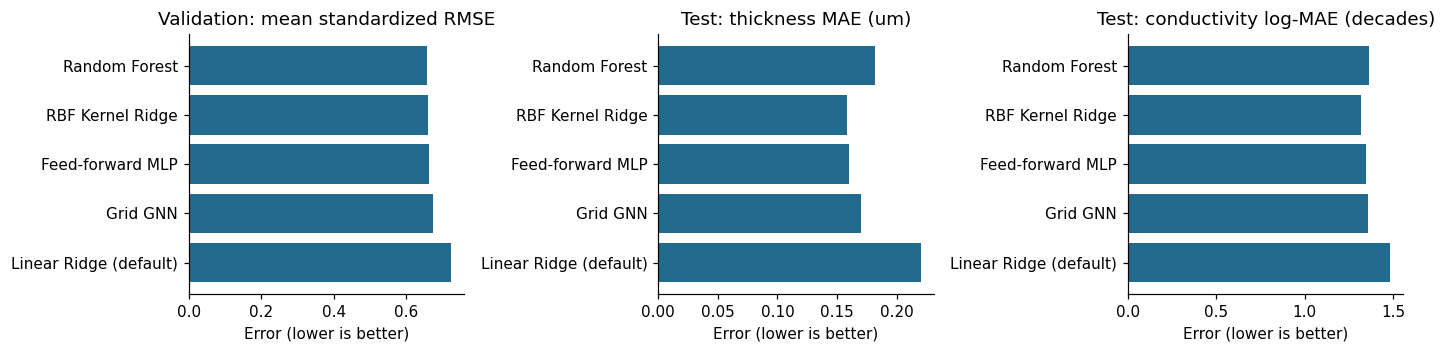

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, column, title in zip(axes,
        ['validation_score', 'test_thickness_MAE_um', 'test_conductivity_log10_MAE'],
        ['Validation: mean standardized RMSE', 'Test: thickness MAE (um)', 'Test: conductivity log-MAE (decades)']):
    ax.barh(comparison.algorithm, comparison[column], color='#236b8e')
    ax.set(title=title, xlabel='Error (lower is better)')
    ax.invert_yaxis()
fig.tight_layout()
fig.savefig(COMPARISON / 'architecture_errors.png', bbox_inches='tight')
plt.show()

## Test-set parity: thickness and conductivity for every algorithm

Each row uses the same untouched test locations. The dashed line is perfect prediction.
Thickness is in µm; conductivity is shown as **log10(S/cm)** because it spans many orders of
magnitude. All rows share the same limits for each property, and all points—including poor
predictions—remain visible. This is reporting, not another round of model selection.

### Plot held-out parity across all architectures

Code Summary: Plots test predictions against measured thickness and log conductivity for each algorithm using shared axes and the same available labels. Results come from verified saved predictions, not refitted models.


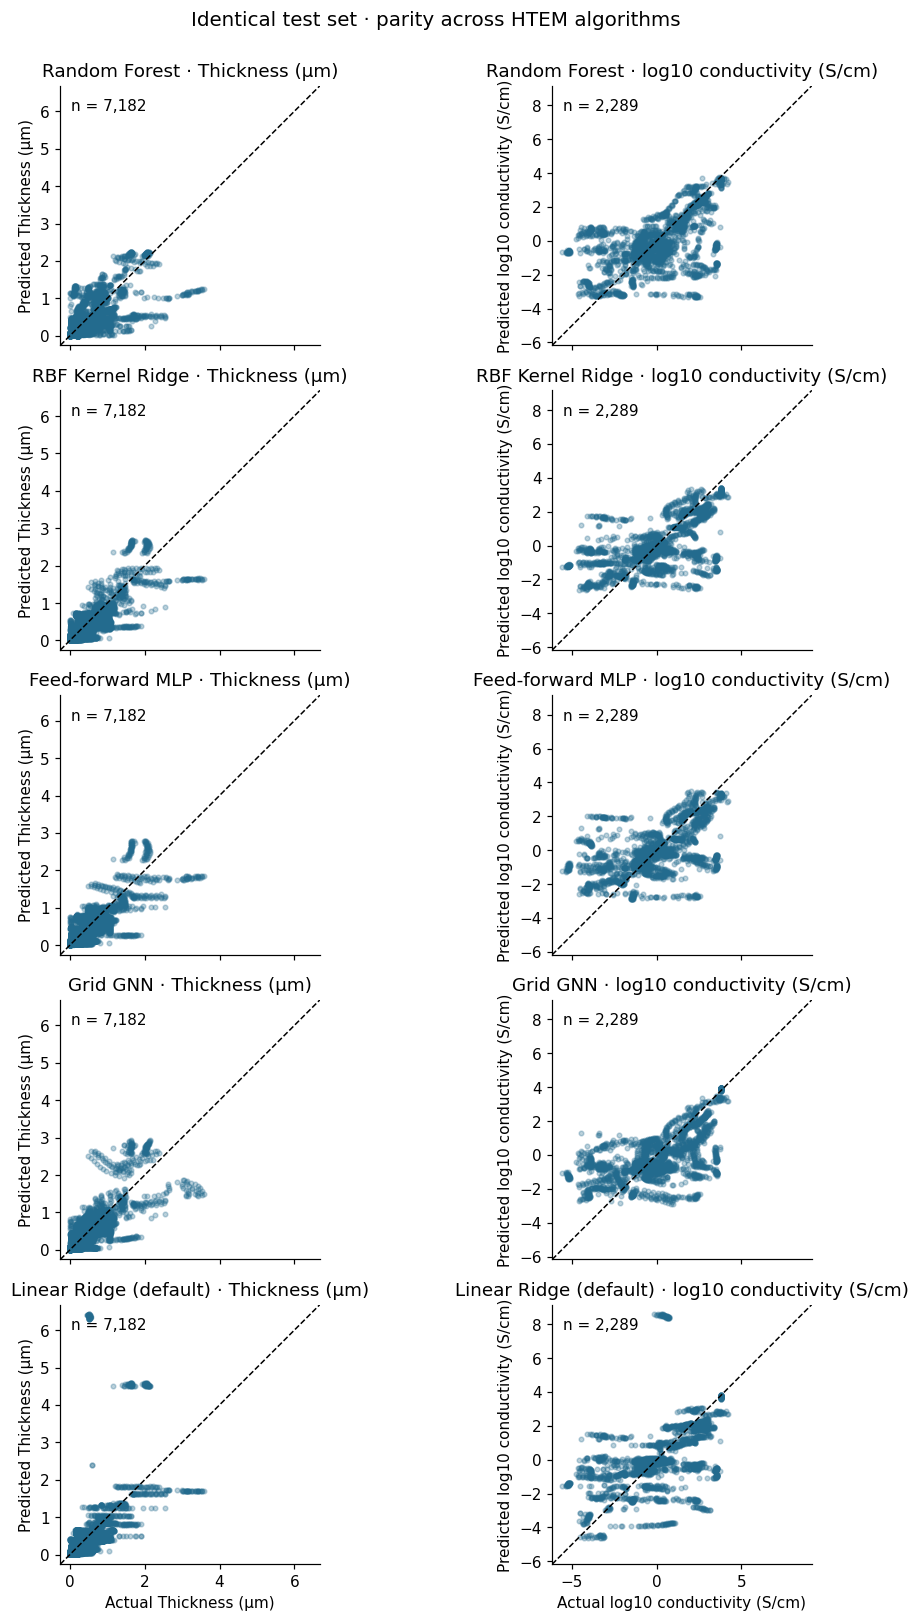

In [3]:
# Test-set parity: read the prediction artifacts already verified above; never refit.
test_predictions = {
    row.experiment_id: pd.read_csv(
        HERE / 'outputs/htem_architectures' / row.experiment_id / 'predictions.csv',
        dtype={'sample_id': str}).query("split == 'test'")
    for row in comparison.itertuples(index=False)
}
properties = [('thickness_um', 'Thickness (µm)'), ('conductivity_S_cm', 'log10 conductivity (S/cm)')]
limits = []
for target, _ in properties:
    values = np.concatenate([table.loc[table['actual_' + target].notna(),
                             ['actual_' + target, 'predicted_' + target]].to_numpy().ravel()
                             for table in test_predictions.values()])
    if not np.isfinite(values).all() or (target == 'conductivity_S_cm' and (values <= 0).any()):
        raise ValueError('Parity plots require finite predictions and positive conductivity; do not silently omit points.')
    if target == 'conductivity_S_cm':
        values = np.log10(values)
    lo, hi = float(values.min()), float(values.max())
    padding = .04 * (hi - lo) if hi > lo else max(abs(lo) * .04, .01)
    limits.append((lo - padding, hi + padding))

fig, axes = plt.subplots(len(comparison), 2, figsize=(10, 3 * len(comparison)),
                         sharex='col', sharey='col', squeeze=False)
for row_index, result in enumerate(comparison.itertuples(index=False)):
    table = test_predictions[result.experiment_id]
    for column, (target, label) in enumerate(properties):
        known = table['actual_' + target].notna()
        actual, predicted = table.loc[known, 'actual_' + target], table.loc[known, 'predicted_' + target]
        if target == 'conductivity_S_cm':
            actual, predicted = np.log10(actual), np.log10(predicted)
        ax = axes[row_index, column]
        ax.scatter(actual, predicted, s=9, alpha=.3, color='#236b8e', rasterized=True)
        ax.plot(limits[column], limits[column], 'k--', lw=1)
        ax.set(xlim=limits[column], ylim=limits[column], title=f'{result.algorithm} · {label}',
               ylabel='Predicted ' + label, xlabel='Actual ' + label if row_index == len(comparison) - 1 else '')
        ax.set_aspect('equal', adjustable='box')
        ax.text(.04, .95, f'n = {len(actual):,}', transform=ax.transAxes, va='top')
fig.suptitle('Identical test set · parity across HTEM algorithms', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .98))
fig.savefig(COMPARISON / 'test_set_parity.png', bbox_inches='tight')
plt.show()

## Interpretation

Use validation for the next hypothesis; reserve test for reporting. If nonlinear models do not win,
say so. Sparse material/recipe coverage, missing process history, and observational selection remain
limitations. One fixed split and seed do not establish a statistically significant improvement.
All models preserve deposition/position identity and use the same held-out grid example; their
individual notebooks contain the maps, parity plots, saved models, and recipe inference functions.